# Cafe Sales Data Analysis

## Project Overview

This project focuses on cleaning, manipulating, and analyzing café sales data using Python and Pandas. The analysis includes Exploratory Data Analysis (EDA) and data visualization to identify sales patterns and business insights.

## Goals

- Clean the cafe sales dataset by identifying and handling missing values, duplicate data, and inconsistent values.
- Convert columns into appropriate data types to ensure the data is accurate and easy to process.
- Manipulate the data by creating, modifying, filtering, and grouping columns as needed.
- Prepare a clean and structured dataset that can be used for further analysis.
- Create visualizations to present key findings.
- Generate useful business insights from the data.

## Workflow

Importing Data -> Explorating Data -> Cleaning Data -> Manipulating Data -> Visualization -> Business Insights

## Tech Stack

Python, Pandas, NumPy, Matplotlib, Seaborn

# Penjelasan Dataset

| Column Name | Data Type | Description |
| :--- | :--- | :--- |
| **Transaction ID** | `object` | ID unik untuk setiap transaksi penjualan yang terjadi. |
| **Item** | `object` | Nama produk atau menu kafe yang dibeli oleh pelanggan. |
| **Quantity** | `int64` | Jumlah atau kuantitas unit produk yang dibeli dalam transaksi tersebut. |
| **Price Per Unit** | `float64` | Harga satuan untuk masing-masing item produk. |
| **Total Spent** | `float64` | Total biaya keseluruhan dari transaksi (hasil perkalian kuantitas dan harga satuan). |
| **Payment Method** | `object` | Metode pembayaran yang digunakan oleh pelanggan. |
| **Location** | `object` | Lokasi atau tipe pelayanan pembelian (misalnya *In-store* atau *Takeaway*), digunakan untuk analisis perilaku pembelian berdasarkan lokasi. |
| **Transaction Date** | `datetime` | Tanggal saat transaksi penjualan tersebut dicatat. |

# Import Data

# Library Yang Digunakan

In [2]:
import pandas as pd # Digunakan untuk mengimpor, mengelola, membersihkan, dan menganalisis data dalam format tabel dua dimensi (tabular data).
import numpy as np # Digunakan untuk komputasi numerik berskala besar, termasuk membantu perhitungan fungsi massa probabilitas (Probability Mass Function / PMF) serta operasi matematika dan analisis statistik.
import matplotlib.pyplot as plt # Digunakan sebagai pustaka dasar untuk merancang dan membuat visualisasi data dua dimensi, seperti grafik garis, diagram batang, dan tebaran titik.
import seaborn as sns # Digunakan untuk membuat visualisasi data bertema statistik yang lebih estetis, modern, dan informatif dengan sintaks yang lebih ringkas.
from scipy import stats # Digunakan untuk melakukan berbagai komputasi, pengujian, dan analisis statistik tingkat lanjut, seperti uji hipotesis, perhitungan nilai probabilitas (p-value), serta pengelolaan berbagai jenis distribusi statistik.

# Load Dataset

In [3]:
df=pd.read_csv(r"C:\Users\HP\Downloads\Cafe_Sales.csv") # Data disimpan di folder 'Downloads' dengan nama 'Cafe_Sales.csv'
df.head() # Menampilkan beberapa baris teratas atau pertama dari dataset

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


# Initial Information

In [4]:
df.info() # show basic dataset information. Main point: number of rows, columns, data types, and non-null count per column.

# All columns except Transaction ID have missing values
# Payment method and Location have the most missing values > 20%
# Quantity, Price Per Unit, Total Spent will be converted to numerical data type
# Transaction Date will be converted to datetime data type

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    10000 non-null  str  
 1   Item              9667 non-null   str  
 2   Quantity          9862 non-null   str  
 3   Price Per Unit    9821 non-null   str  
 4   Total Spent       9827 non-null   str  
 5   Payment Method    7421 non-null   str  
 6   Location          6735 non-null   str  
 7   Transaction Date  9841 non-null   str  
dtypes: str(8)
memory usage: 1.1 MB


In [5]:
df.describe() # how basic statistical information. Key point: see the range and distribution of numeric columns

# Transaction ID
# Total Rows (count): 10,000 transactions.
# Uniqueness: All 10,000 IDs are unique (freq: 1), meaning there are no duplicate transaction records.

# Item
# Missing Values: 333 missing records (count is 9,667 out of 10,000).
# Categories (unique): 10 distinct items.
# Most Common (top): "Juice" appears 1,171 times.

# Quantity
# Missing Values: 138 missing records (count is 9,862).
# Uniqueness: '7' distinct quantity values.
# Most Common (top): A quantity of '5' appears most frequently (2,013 times).

# Price Per Unit
# Missing Values: 179 missing records (count is 9,821).
# Uniqueness: 8 distinct price points.
# Most Common (top): A unit price of 3.0 occurs 2,429 times.

# Total Spent
# Missing Values: 173 missing records (count is 9,827).
# Uniqueness: 19 distinct calculated totals.
# Most Common (top): A total spent value of 6.0 occurs 979 times.

# Payment Method
# Missing Values: 2,579 missing records (only 7,421 non-null entries).
# Uniqueness: 5 distinct payment types.
# Most Common (top): "Digital Wallet" is the most frequent method (2,291 times).

# Location
# Missing Values: 3,265 missing records (only 6,735 non-null entries).
# Uniqueness: 4 distinct locations.
# Most Common (top): "Takeaway" is the most common location type (3,022 times).

# Transaction Date
# Missing Values: 159 missing records (count is 9,841).
# Uniqueness: 367 distinct dates/values.
# Most Common (top): Labeled as "UNKNOWN" with a frequency of 159, indicating placeholder or dirty data.

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
count,10000,9667,9862,9821,9827,7421,6735,9841
unique,10000,10,7,8,19,5,4,367
top,TXN_1961373,Juice,5,3.0,6.0,Digital Wallet,Takeaway,UNKNOWN
freq,1,1171,2013,2429,979,2291,3022,159


# Checking Missing Values

In [6]:
missing_values = df.isnull().sum() # more detailed check of missing values in each column
percentage_missing = (missing_values / len(df)) * 100 # percentage of missing values

print("Missing Values:")
print(missing_values)

print("\nPercentage of Missing Values:")
print(percentage_missing.round(2))

Missing Values:
Transaction ID         0
Item                 333
Quantity             138
Price Per Unit       179
Total Spent          173
Payment Method      2579
Location            3265
Transaction Date     159
dtype: int64

Percentage of Missing Values:
Transaction ID       0.00
Item                 3.33
Quantity             1.38
Price Per Unit       1.79
Total Spent          1.73
Payment Method      25.79
Location            32.65
Transaction Date     1.59
dtype: float64


# Memeriksa Data Duplikasi

In [7]:
duplicated_values = df.duplicated().sum() # Checking duplicate values per column
print("Duplicated Values:", duplicated_values)

Duplicated Values: 0


Tidak terdapat data duplikasi

# Memeriksa Nilai Unik

In [8]:
for col in df.columns:
    jumlah_unik = df[col].nunique()
    print(f"Kolom {col}: {jumlah_unik} nilai unik")

Kolom Transaction ID: 10000 nilai unik
Kolom Item: 10 nilai unik
Kolom Quantity: 7 nilai unik
Kolom Price Per Unit: 8 nilai unik
Kolom Total Spent: 19 nilai unik
Kolom Payment Method: 5 nilai unik
Kolom Location: 4 nilai unik
Kolom Transaction Date: 367 nilai unik


# Melihat seluruh nilai unik (distinct values)
Mengecek apakah ada typo atau tidak

In [9]:
for col in df.columns:
    print(f"\n=== {col} ===")
    print(df[col].unique())


=== Transaction ID ===
<ArrowStringArray>
['TXN_1961373', 'TXN_4977031', 'TXN_4271903', 'TXN_7034554', 'TXN_3160411',
 'TXN_2602893', 'TXN_4433211', 'TXN_6699534', 'TXN_4717867', 'TXN_2064365',
 ...
 'TXN_1538510', 'TXN_3897619', 'TXN_2739140', 'TXN_4766549', 'TXN_7851634',
 'TXN_7672686', 'TXN_9659401', 'TXN_5255387', 'TXN_7695629', 'TXN_6170729']
Length: 10000, dtype: str

=== Item ===
<ArrowStringArray>
[  'Coffee',     'Cake',   'Cookie',    'Salad', 'Smoothie',  'UNKNOWN',
 'Sandwich',        nan,    'ERROR',    'Juice',      'Tea']
Length: 11, dtype: str

=== Quantity ===
<ArrowStringArray>
['2', '4', '5', '3', '1', 'ERROR', 'UNKNOWN', nan]
Length: 8, dtype: str

=== Price Per Unit ===
<ArrowStringArray>
['2.0', '3.0', '1.0', '5.0', '4.0', '1.5', nan, 'ERROR', 'UNKNOWN']
Length: 9, dtype: str

=== Total Spent ===
<ArrowStringArray>
[    '4.0',    '12.0',   'ERROR',    '10.0',    '20.0',     '9.0',    '16.0',
    '15.0',    '25.0',     '8.0',     '5.0',     '3.0',     '6.0',     

### Ringkasan & Analisis Data

> **Catatan Utama:** Data memerlukan pembersihan menyeluruh (*data cleaning*) sebelum bisa digunakan untuk analisis lanjutan.

* **Masalah Kualitas Data**
  Hampir seluruh kolom (kecuali `Transaction ID`) tercemar oleh nilai-nilai kotor seperti `'UNKNOWN'`, `'ERROR'`, dan `nan` (*missing value*). 

* **Tipe Data Tidak Sesuai**
  Semua kolom terbaca sebagai string (`ArrowStringArray`), termasuk kolom angka seperti `Quantity`, `Price Per Unit`, dan `Total Spent`. Kolom-kolom ini perlu dikonversi ke tipe data numerik (*integer/float*), begitu juga `Transaction Date` ke format *datetime*.

* **Karakteristik Kolom:**
  1. **`Transaction ID`**: Berisi 10.000 ID unik sebagai pengenal transaksi.
  2. **`Item`, `Payment Method`, & `Location`**: Memuat kategori yang valid (seperti *Coffee*, *Cash*, *Takeaway*), namun masih tercampur data *error*.
  3. **`Transaction Date`**: Menggunakan format tanggal (`YYYY-MM-DD`) dengan total 368 variasi tanggal yang tercatat.

# Data Cleaning

### Membuat data frame baru salinan dari df agar ketika digunakan untuk analisis tidak merusak data asli

In [10]:
df_clean = df.copy()

### Mengubah Tipe Data Kolom 'Transaction Date' menjadi format datetime

In [11]:
df_clean["Transaction Date"] = pd.to_datetime(
    df_clean["Transaction Date"],
    format = "%Y-%m-%d",
    errors = "coerce"
)
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    10000 non-null  str           
 1   Item              9667 non-null   str           
 2   Quantity          9862 non-null   str           
 3   Price Per Unit    9821 non-null   str           
 4   Total Spent       9827 non-null   str           
 5   Payment Method    7421 non-null   str           
 6   Location          6735 non-null   str           
 7   Transaction Date  9540 non-null   datetime64[us]
dtypes: datetime64[us](1), str(7)
memory usage: 986.9 KB


### Mengubah Tipe Data Kolom 'Quantity','Price Per Unit','Total Spent' menjadi numeric

In [12]:
df_clean["Quantity"] = pd.to_numeric(
    df_clean["Quantity"],
    errors="coerce"
)

df_clean["Price Per Unit"] = pd.to_numeric(
    df_clean["Price Per Unit"].round(2),
    errors="coerce"
)

df_clean["Total Spent"] = pd.to_numeric(
    df_clean["Total Spent"].round(2),
    errors="coerce"
)
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    10000 non-null  str           
 1   Item              9667 non-null   str           
 2   Quantity          9521 non-null   float64       
 3   Price Per Unit    9467 non-null   float64       
 4   Total Spent       9498 non-null   float64       
 5   Payment Method    7421 non-null   str           
 6   Location          6735 non-null   str           
 7   Transaction Date  9540 non-null   datetime64[us]
dtypes: datetime64[us](1), float64(3), str(4)
memory usage: 908.9 KB


### Mengganti 'UNKNOWN' dan ERROR menjadi Nan
### Mengubah nilsi kosong pada data kategorikal menjadi 'Unknown'
### Mengubah nilai kosong pada data numerikal menjadi median
### Mengubah Transaction Date menjadi tipe data datetime

In [13]:
# Replacing UNKNOWN and ERROR to Nan
df_clean = df_clean.replace(['UNKNOWN', 'ERROR'], pd.NA)

# Kategorikal -> Unknown
df_clean["Item"] = df_clean["Item"].fillna("Unknown")

# Numerikal -> Median
df_clean["Quantity"] = df_clean["Quantity"].fillna(
    df_clean["Quantity"].median()
)
df_clean["Price Per Unit"] = df_clean["Price Per Unit"].fillna(
    df_clean["Price Per Unit"].median()
)

# Total Spent = Quantity * Price Per Unit
df_clean["Total Spent"] = df_clean["Total Spent"].fillna(
    df_clean["Quantity"] * df_clean["Price Per Unit"]
)

# Transaction -> Mode
df_clean["Transaction Date"] = df_clean["Transaction Date"].fillna(
    df_clean["Transaction Date"].mode()[0]
)

df_clean.head()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2.0,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4.0,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4.0,1.0,4.0,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2.0,5.0,10.0,NaN,NaN,2023-04-27
4,TXN_3160411,Coffee,2.0,2.0,4.0,Digital Wallet,In-store,2023-06-11


### Mengganti tipe data Quantity dari float menjadi int karena quantity produk tidak boleh koma

In [14]:
df_clean["Quantity"] = df_clean["Quantity"].astype(int)
df_clean["Quantity"]

0       2
1       4
2       4
3       2
4       2
       ..
9995    2
9996    3
9997    4
9998    3
9999    3
Name: Quantity, Length: 10000, dtype: int64

### Memeriksa apakah tipe data Quantity, Price Per Unit, Total Spent dan Transaction Date sudah terganti atau belum

In [15]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    10000 non-null  str           
 1   Item              10000 non-null  str           
 2   Quantity          10000 non-null  int64         
 3   Price Per Unit    10000 non-null  float64       
 4   Total Spent       10000 non-null  float64       
 5   Payment Method    6822 non-null   str           
 6   Location          6039 non-null   str           
 7   Transaction Date  10000 non-null  datetime64[us]
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 902.9 KB


In [16]:
df_clean.describe()

,Quantity,Price Per Unit,Total Spent,Transaction Date
count,10000.000000,10000.00000,10000.000000,10000
mean,3.027100,2.95265,8.930750,2023-06-25 05:52:13.440000
min,1.000000,1.00000,1.000000,2023-01-01 00:00:00
25%,2.000000,2.00000,4.000000,2023-03-19 00:00:00
50%,3.000000,3.00000,8.000000,2023-06-24 00:00:00
75%,4.000000,4.00000,12.000000,2023-09-27 00:00:00
max,5.000000,5.00000,25.000000,2023-12-31 00:00:00
std,1.384614,1.24396,5.997122,NaN


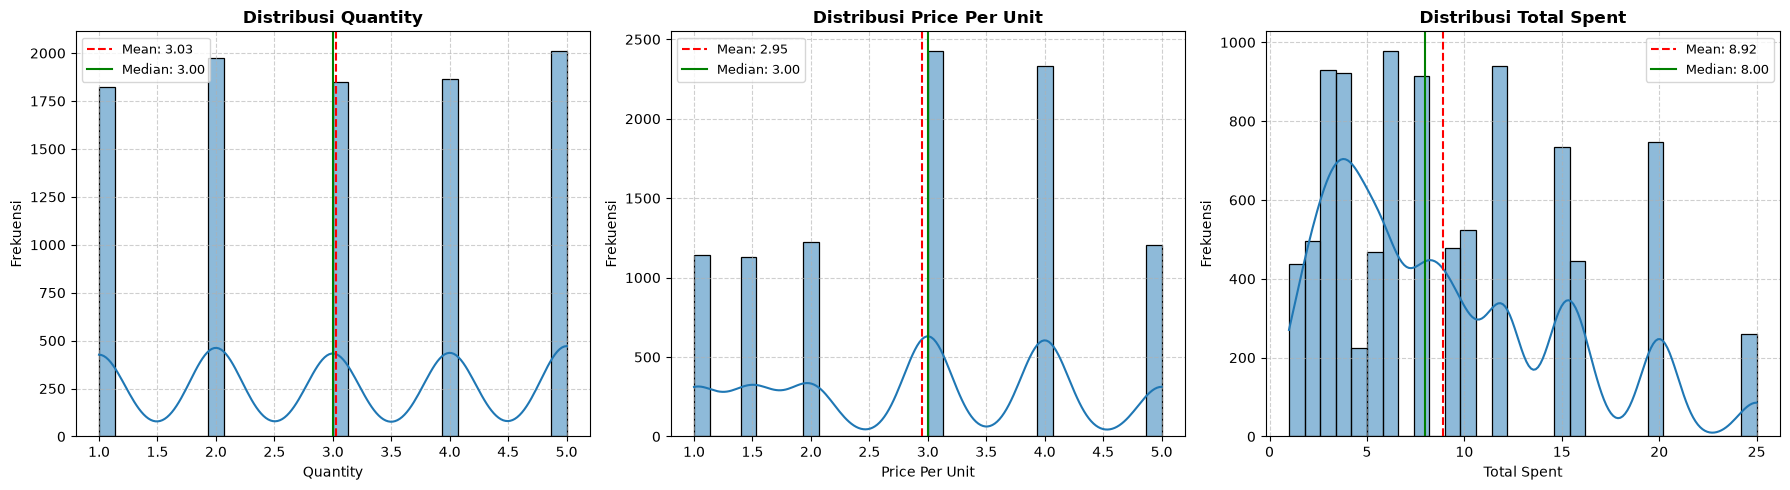

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Salin dataframe utama ke df_clean dan bersihkan nilai error/unknown
df_clean = df.copy()
df_clean.replace(['ERROR', 'UNKNOWN'], np.nan, inplace=True)

cols = ['Quantity', 'Price Per Unit', 'Total Spent']

# 2. Membersihkan kolom numerik dari teks error/unknown
for col in cols:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

# 3. Menyiapkan kanvas dengan 3 subplot (1 baris, 3 kolom)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 4. Looping untuk membuat histogram dengan warna default dan grid
for i, col in enumerate(cols):
    # Menggunakan df_clean yang sudah dibersihkan
    sns.histplot(df_clean[col].dropna(), kde=True, ax=axes[i], bins=30)
    
    axes[i].set_title(f'Distribusi {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frekuensi')
    
    # Mengaktifkan grid agar grafik lebih mudah dibaca
    axes[i].grid(True, linestyle='--', alpha=0.6)
    
    # Menambahkan garis Mean (merah putus-putus) dan Median (hijau)
    mean_val = df_clean[col].mean()
    median_val = df_clean[col].median()
    axes[i].axvline(mean_val, color='red', linestyle='--', label=f'Mean: {mean_val:.2f}')
    axes[i].axvline(median_val, color='green', linestyle='-', label=f'Median: {median_val:.2f}')
    axes[i].legend(fontsize=9)

# Merapikan dan menampilkan grafik
plt.tight_layout()
plt.show()

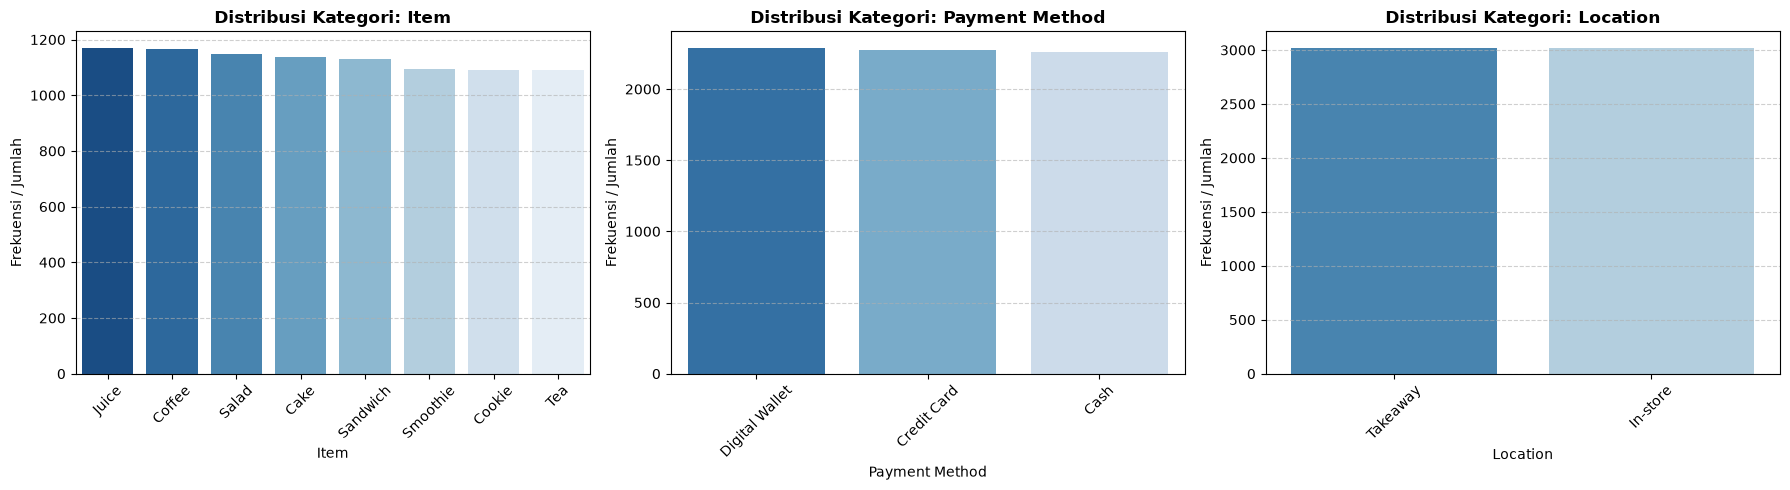

In [18]:
# 2. Menentukan kolom kategorikal yang ingin dianalisis
categorical_cols = ['Item', 'Payment Method', 'Location']

# 3. Menyiapkan kanvas dengan 3 subplot (1 baris, 3 kolom)
fig, axes = plt.subplots(1, len(categorical_cols), figsize=(18, 5))

# 4. Looping untuk membuat bar chart bebas warning
for i, col in enumerate(categorical_cols):
    data_counts = df_clean[col].value_counts()
    
    # Menggunakan x sebagai hue dan menonaktifkan legend sesuai standar baru seaborn
    sns.barplot(
        x=data_counts.index, 
        y=data_counts.values, 
        ax=axes[i], 
        hue=data_counts.index, 
        palette='Blues_r', 
        legend=False
    )
    
    axes[i].set_title(f'Distribusi Kategori: {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frekuensi / Jumlah')
    
    # Merotasi label sumbu X agar mudah dibaca
    axes[i].tick_params(axis='x', rotation=45)
    
    # Mengaktifkan grid pada sumbu Y
    axes[i].grid(True, linestyle='--', alpha=0.6, axis='y')

# Merapikan tata letak dan menampilkan grafik
plt.tight_layout()
plt.show()

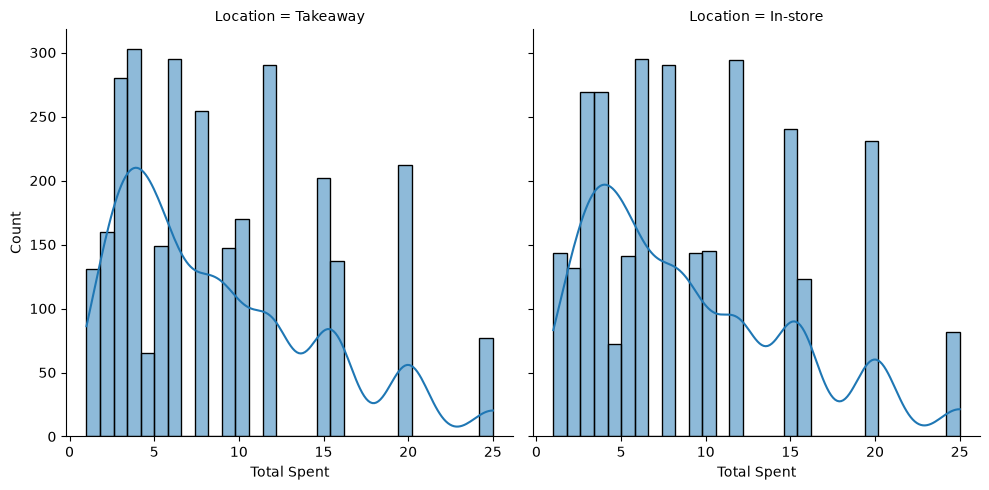

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

# Membuat FacetGrid berdasarkan kolom 'Location'
g = sns.FacetGrid(df_clean, col="Location", height=5, aspect=1)

# Memetakan data ke dalam grid menggunakan histplot (histogram)
g.map(sns.histplot, "Total Spent", kde=True, bins=30)

# Menampilkan grafik
plt.show()

In [20]:
df_clean.head()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2.0,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4.0,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4.0,1.0,NaN,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2.0,5.0,10.0,NaN,NaN,2023-04-27
4,TXN_3160411,Coffee,2.0,2.0,4.0,Digital Wallet,In-store,2023-06-11


In [21]:
print(df_clean["Location"].value_counts(dropna=False))
print(df_clean["Payment Method"].value_counts(dropna=False))

Location
NaN         3961
Takeaway    3022
In-store    3017
Name: count, dtype: int64
Payment Method
NaN               3178
Digital Wallet    2291
Credit Card       2273
Cash              2258
Name: count, dtype: int64


# 4. Outlier Detection

### Visualisasi Outlier pada Quantity

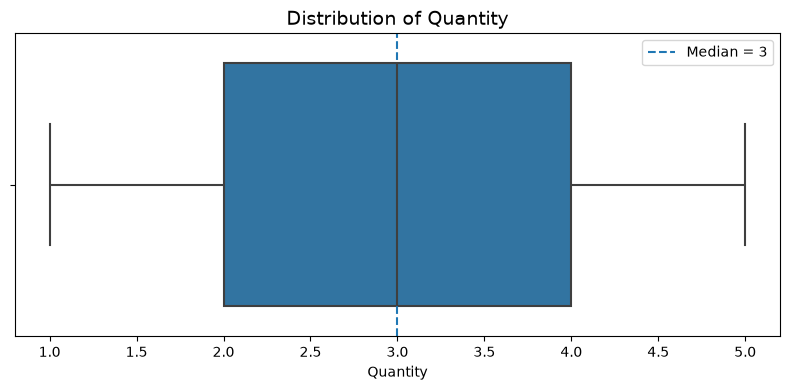

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

sns.boxplot(
    x=df_clean["Quantity"],
    linewidth=1.5,
    fliersize=5
)

median = df_clean["Quantity"].median()

plt.axvline(
    median,
    linestyle="--",
    linewidth=1.5,
    label=f"Median = {median:.0f}"
)

plt.title("Distribution of Quantity", fontsize=14)
plt.xlabel("Quantity")
plt.legend()

plt.tight_layout()
plt.show()

Kesimpulan: Boxplot ini menunjukkan bahwa distribusi quantity cukup simetris, karena median berada di tengah kotak. Tidak ada outlier yang signifikan, karena tidak ada titik di luar whiskers. Quantity berada dalam rentang 1 hingga 5 dengan sebagian besar data terkonsentrasi antara 2 hingga 4. 

### Visualisasi Outlier pada Price Per Unit

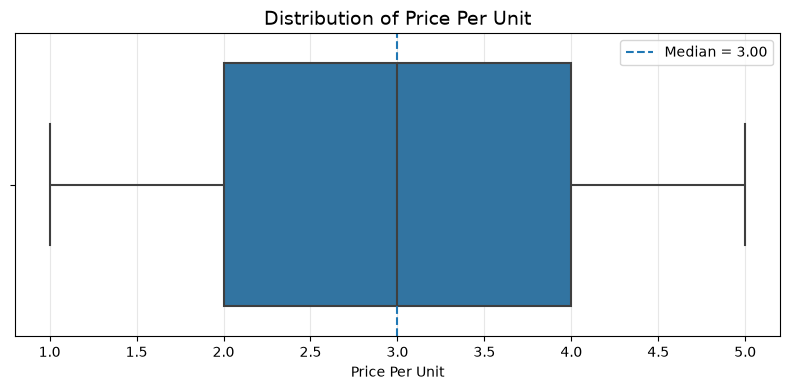

In [23]:
plt.figure(figsize=(8, 4))

sns.boxplot(
    x=df_clean["Price Per Unit"],
    linewidth=1.5,
    fliersize=5
)

median = df_clean["Price Per Unit"].median()

plt.axvline(
    median,
    linestyle="--",
    linewidth=1.5,
    label=f"Median = {median:.2f}"
)

plt.title("Distribution of Price Per Unit", fontsize=14)
plt.xlabel("Price Per Unit")
plt.grid(axis="x", alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

Kesimpulan: Boxplot ini menunjukkan bahwa distribusi Price per Unit cukup simetris, karena median berada di tengah kotak. Tidak ada outlier yang signifikan, karena tidak ada titik di luar whiskers. Price per Unit berada dalam rentang 1 dollar hingga 5 dollar dengan sebagian besar data terkonsentrasi antara 2 dollar hingga 4 dollar. 

### Visualisasi Outlier pada Total Spent

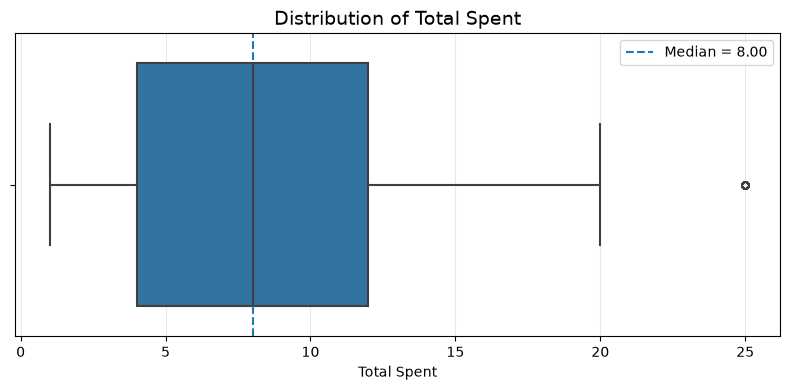

In [24]:
plt.figure(figsize=(8, 4))

sns.boxplot(
    x=df_clean["Total Spent"],
    linewidth=1.5,
    fliersize=5
)

median = df_clean["Total Spent"].median()

plt.axvline(
    median,
    linestyle="--",
    linewidth=1.5,
    label=f"Median = {median:.2f}"
)

plt.title("Distribution of Total Spent", fontsize=14)
plt.xlabel("Total Spent")
plt.grid(axis="x", alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

Kesimpulan: Boxplot menunjukkan bahwa sebagian besar nilai Total Spent berada pada kisaran sekitar 4 dollar hingga 12 dollar, dengan median sekitar 8 dollar. Nilai terendah yang masih berada dalam batas normal sekitar 1 dollar, sedangkan nilai tertinggi yang masih dianggap normal sekitar 20 dollar. Terdapat satu nilai sekitar 25 dollar yang berada di luar whisker, sehingga dapat dikategorikan sebagai outlier.

### Pengecekan Outlier pada Kolom Kategorikal Menggunakan Frequency Encoding + IQR

### Outlier pada Kolom Item

In [25]:
# Frequency Encoding Item
frequency = df_clean["Item"].value_counts(
    dropna=False
)

# IQR
Q1 = frequency.quantile(0.25)
Q3 = frequency.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Deteksi kategori
outlier_category = frequency[
    (frequency < lower_bound) |
    (frequency > upper_bound)
]

print("Frekuensi kategori:")
print(frequency)

print("\nLower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

print("\nKategori yang terdeteksi sebagai outlier:")
print(outlier_category)

Frekuensi kategori:
Item
Juice       1171
Coffee      1165
Salad       1148
Cake        1139
Sandwich    1131
Smoothie    1096
Cookie      1092
Tea         1089
NaN          969
Name: count, dtype: int64

Lower Bound: 1008.0
Upper Bound: 1232.0

Kategori yang terdeteksi sebagai outlier:
Item
NaN    969
Name: count, dtype: int64


## Membuat kolom baru

In [26]:
# Creating a new column 'Spending Level'
df_clean.loc[:, "Spending Level"] = df_clean["Total Spent"].apply(
    lambda x: "Low" if x <= 4
    else "Medium" if x <= 12
    else "High"
)

# Creating a new column 'Day' and 'Month'
df_clean['Transaction Date'] = pd.to_datetime(df_clean['Transaction Date'])

df_clean['Day'] = df_clean['Transaction Date'].dt.day_name()
df_clean['Month'] = df_clean['Transaction Date'].dt.month_name()

# Calculating the Transaction Date Range
duration = (
    df_clean["Transaction Date"].max()
    - df_clean["Transaction Date"].min()
)
print(duration)

df_clean

364 days 00:00:00


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date,Spending Level,Day,Month
0,TXN_1961373,Coffee,2.0,2.0,4.0,Credit Card,Takeaway,2023-09-08,Low,Friday,September
1,TXN_4977031,Cake,4.0,3.0,12.0,Cash,In-store,2023-05-16,Medium,Tuesday,May
2,TXN_4271903,Cookie,4.0,1.0,NaN,Credit Card,In-store,2023-07-19,High,Wednesday,July
3,TXN_7034554,Salad,2.0,5.0,10.0,NaN,NaN,2023-04-27,Medium,Thursday,April
4,TXN_3160411,Coffee,2.0,2.0,4.0,Digital Wallet,In-store,2023-06-11,Low,Sunday,June
...,...,...,...,...,...,...,...,...,...,...,...
9995,TXN_7672686,Coffee,2.0,2.0,4.0,NaN,NaN,2023-08-30,Low,Wednesday,August
9996,TXN_9659401,NaN,3.0,NaN,3.0,Digital Wallet,NaN,2023-06-02,Low,Friday,June
9997,TXN_5255387,Coffee,4.0,2.0,8.0,Digital Wallet,NaN,2023-03-02,Medium,Thursday,March
9998,TXN_7695629,Cookie,3.0,NaN,3.0,Digital Wallet,NaN,2023-12-02,Low,Saturday,December


# 6. Exploratory Data Analysis (EDA)

### 6.1. Item Analysis

In [27]:
print("="*60)
print("Top 10 Sellling Items:")
print("="*60)
print(df_clean['Item'].value_counts().head(10))
print("="*60)
# Top 10 Revenue Generating Item
print("Top 10 Revenue Generating Items:")
print("="*60)
print(df_clean.groupby('Item')['Total Spent'].sum().sort_values(ascending=False).head(10))

Top 10 Sellling Items:
Item
Juice       1171
Coffee      1165
Salad       1148
Cake        1139
Sandwich    1131
Smoothie    1096
Cookie      1092
Tea         1089
Name: count, dtype: int64
Top 10 Revenue Generating Items:
Item
Salad       16605.0
Sandwich    12956.0
Smoothie    12556.0
Juice        9984.0
Cake         9933.0
Coffee       6784.0
Tea          4735.5
Cookie       3070.0
Name: Total Spent, dtype: float64


### 6.2. Transaction Date Analysis

In [28]:
print("="*60)
print("Revenue by Month:")
print("="*60)
print(df_clean.groupby("Month")["Total Spent"].sum().sort_values(ascending=False))
print("="*60)
# Top 10 Revenue Generating Item
print("Revenue by Day:")
print("="*60)
print(df_clean.groupby("Day")["Total Spent"].sum().sort_values(ascending=False))

Revenue by Month:
Month
June         7071.5
October      7040.5
August       6904.0
January      6845.0
March        6822.0
December     6801.0
April        6730.5
May          6674.0
July         6574.0
November     6532.5
September    6501.5
February     6304.0
Name: Total Spent, dtype: float64
Revenue by Day:
Day
Thursday     11874.5
Sunday       11726.5
Friday       11640.0
Monday       11633.5
Tuesday      11437.0
Saturday     11424.0
Wednesday    11065.0
Name: Total Spent, dtype: float64


### 6.3. Payment Method Analysis

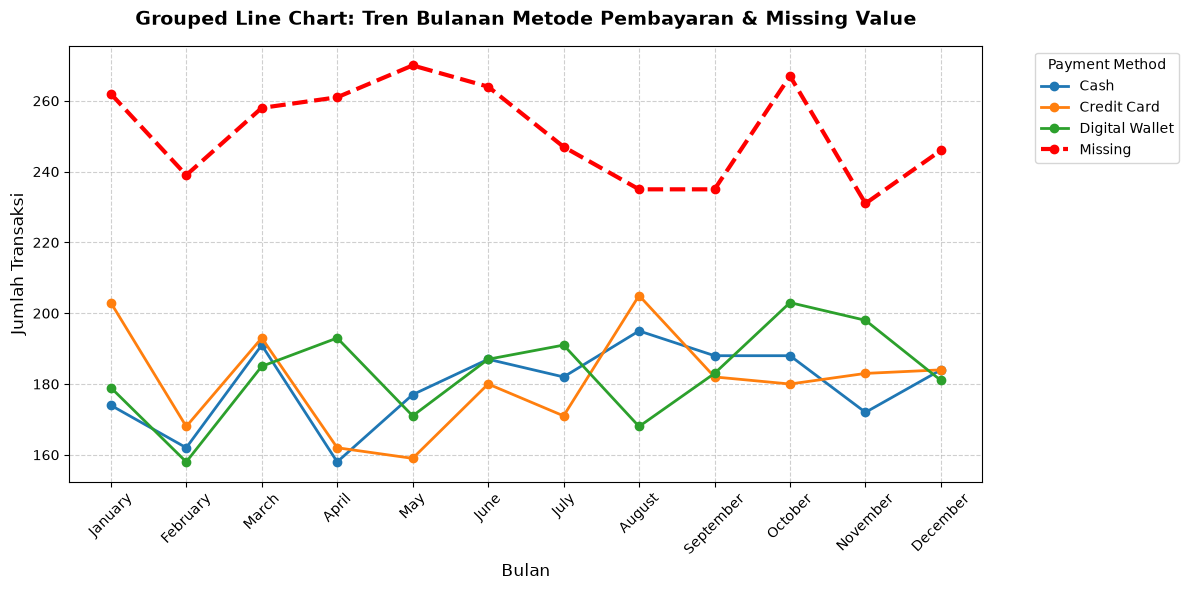

In [29]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Persiapan Data: Salin df_clean dan tangani NaN pada Payment Method menjadi 'Missing'
df_season = df_clean.copy()
df_season['Payment Method'] = df_season['Payment Method'].fillna('Missing')

# 2. Tentukan urutan bulan secara kronologis (Januari - Desember)
month_order = [
    'January', 'February', 'March', 'April', 'May', 'June', 
    'July', 'August', 'September', 'October', 'November', 'December'
]

# 3. Buat crosstab (tabel silang) antara Bulan dan Payment Method
seasonality_table = pd.crosstab(df_season['Month'], df_season['Payment Method'])

# Sesuaikan urutan baris berdasarkan kalender bulan yang ada di data
existing_months = [m for m in month_order if m in seasonality_table.index]
seasonality_table = seasonality_table.reindex(existing_months)

# 4. Membuat Grouped Line Chart
plt.figure(figsize=(12, 6))

# Looping untuk membuat garis terpisah bagi setiap metode pembayaran (termasuk 'Missing')
for payment_method in seasonality_table.columns:
    # Berikan gaya khusus (garis tebal putus-putus) untuk kategori 'Missing' agar mudah dianalisis
    if payment_method == 'Missing':
        linewidth = 3
        linestyle = '--'
        color = 'red'
    else:
        linewidth = 2
        linestyle = '-'
        color = None
        
    plt.plot(
        seasonality_table.index, 
        seasonality_table[payment_method], 
        marker='o', 
        linestyle=linestyle, 
        linewidth=linewidth, 
        markersize=6, 
        label=str(payment_method),
        color=color
    )

# 5. Pengaturan Estetika Grafik
plt.title('Grouped Line Chart: Tren Bulanan Metode Pembayaran & Missing Value', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Bulan', fontsize=12)
plt.ylabel('Jumlah Transaksi', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Payment Method', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

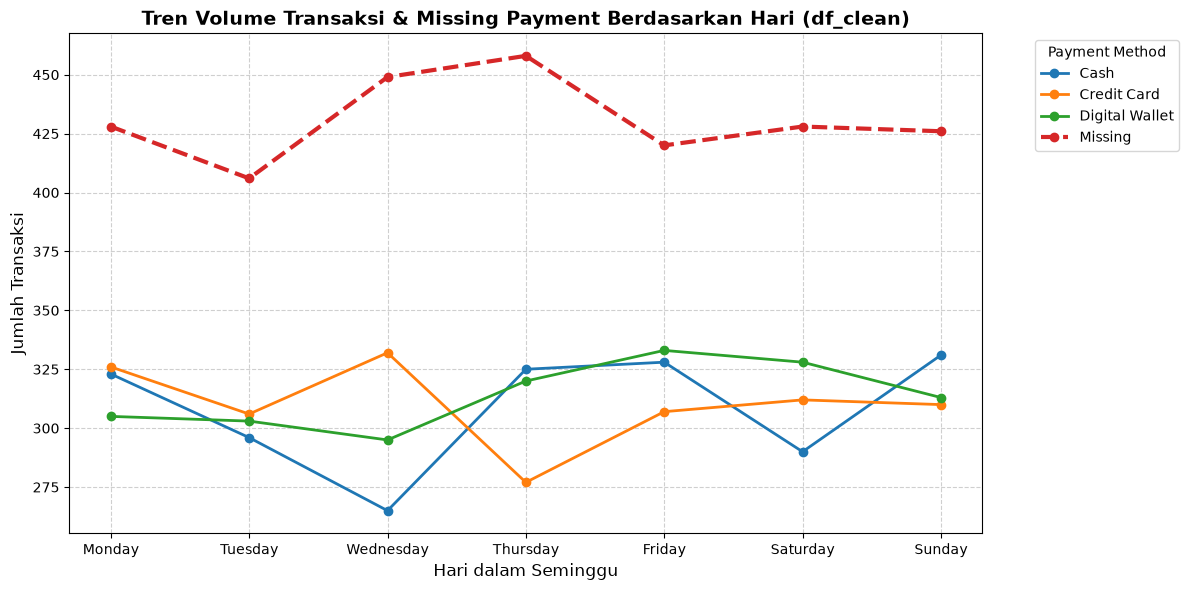

In [30]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Buat salinan dataframe dan ubah nilai NaN pada Payment Method menjadi 'Missing'
df_plot = df_clean.copy()
df_plot['Payment Method'] = df_plot['Payment Method'].fillna('Missing')

# 2. Tentukan urutan hari agar tampil secara kronologis (Senin - Minggu)
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# 3. Buat tabel silang (crosstab) antara Day dan Payment Method (termasuk kategori 'Missing')
payment_by_day = pd.crosstab(df_plot['Day'], df_plot['Payment Method'])

# Sesuaikan urutan baris berdasarkan day_order
payment_by_day = payment_by_day.reindex(day_order)

# 4. Membuat Line Chart
plt.figure(figsize=(12, 6))

# Looping untuk membuat garis terpisah bagi setiap metode pembayaran (termasuk 'Missing')
for payment_method in payment_by_day.columns:
    # Berikan warna khusus atau ketebalan lebih jika itu adalah garis 'Missing' agar mudah dianalisis
    line_width = 3 if payment_method == 'Missing' else 2
    line_style = '--' if payment_method == 'Missing' else '-'
    
    plt.plot(
        payment_by_day.index, 
        payment_by_day[payment_method], 
        marker='o', 
        linestyle=line_style, 
        linewidth=line_width, 
        markersize=6, 
        label=str(payment_method)
    )

# 5. Pengaturan Tampilan Grafik
plt.title('Tren Volume Transaksi & Missing Payment Berdasarkan Hari (df_clean)', fontsize=14, fontweight='bold')
plt.xlabel('Hari dalam Seminggu', fontsize=12)
plt.ylabel('Jumlah Transaksi', fontsize=12)
plt.legend(title='Payment Method', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

=== TABEL SILANG: METODE PEMBAYARAN PER ITEM ===
Payment Method  Cash  Credit Card  Digital Wallet  Missing
Item                                                      
Cake             276          253             246      364
Coffee           244          242             265      414
Cookie           245          253             265      329
Juice            266          276             285      344
Salad            285          279             240      344
Sandwich         253          256             255      367
Smoothie         236          252             255      353
Tea              241          232             254      362
Unknown Item     212          230             226      301


<Figure size 1200x600 with 0 Axes>

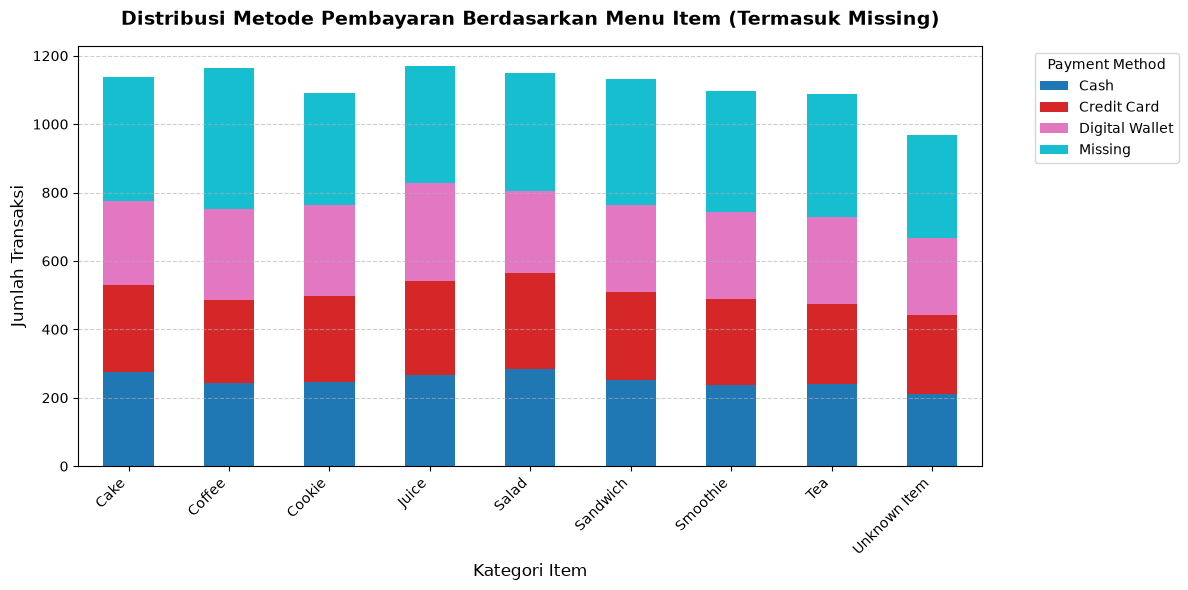

In [31]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Persiapan Data: Salin df_clean dan tangani NaN pada Payment Method dan Item
df_item_pay = df_clean.copy()
df_item_pay['Payment Method'] = df_item_pay['Payment Method'].fillna('Missing')
df_item_pay['Item'] = df_item_pay['Item'].fillna('Unknown Item')

# 2. Buat crosstab (tabel silang) antara Item dan Payment Method
payment_by_item = pd.crosstab(df_item_pay['Item'], df_item_pay['Payment Method'])

print("=== TABEL SILANG: METODE PEMBAYARAN PER ITEM ===")
print(payment_by_item)

# 3. Membuat Stacked Bar Chart untuk Visualisasi
plt.figure(figsize=(12, 6))

# Plotting Stacked Bar Chart
ax = payment_by_item.plot(
    kind='bar', 
    stacked=True, 
    colormap='tab10', # Palet warna yang kontras untuk setiap metode pembayaran
    edgecolor='none',
    figsize=(12, 6)
)

# 4. Pengaturan Estetika Grafik
plt.title('Distribusi Metode Pembayaran Berdasarkan Menu Item (Termasuk Missing)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Kategori Item', fontsize=12)
plt.ylabel('Jumlah Transaksi', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Payment Method', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [32]:
print("PAYMENT METHOD ANALYSIS")
print("="*60)

# 1. Distribution
print("\nPayment Method Distribution:")
print(df_clean["Payment Method"].value_counts())

# 2. Percentage
print("\nPayment Method Percentage:")
print(
    df_clean["Payment Method"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

# 3. Revenue
print("\nRevenue by Payment Method:")
print(
    df_clean.groupby("Payment Method")["Total Spent"]
    .sum()
    .sort_values(ascending=False)
)

# 4. Average Spend
print("\nAverage Spend by Payment Method:")
print(
    df_clean.groupby("Payment Method")["Total Spent"]
    .mean()
    .sort_values(ascending=False)
)

# 5. Average Quantity
print("\nAverage Quantity by Payment Method:")
print(
    df_clean.groupby("Payment Method")["Quantity"]
    .mean()
    .sort_values(ascending=False)
)

# 6. Payment Method by Location
print("\nPayment Method by Location:")
print(
    pd.crosstab(
        df_clean["Location"],
        df_clean["Payment Method"]
    )
)

PAYMENT METHOD ANALYSIS

Payment Method Distribution:
Payment Method
Digital Wallet    2291
Credit Card       2273
Cash              2258
Name: count, dtype: int64

Payment Method Percentage:
Payment Method
Digital Wallet    33.58
Credit Card       33.32
Cash              33.10
Name: proportion, dtype: float64

Revenue by Payment Method:
Payment Method
Credit Card       19599.0
Digital Wallet    19578.0
Cash              19326.0
Name: Total Spent, dtype: float64

Average Spend by Payment Method:
Payment Method
Cash              9.064728
Credit Card       9.027637
Digital Wallet    8.951989
Name: Total Spent, dtype: float64

Average Quantity by Payment Method:
Payment Method
Digital Wallet    3.046288
Cash              3.031555
Credit Card       3.021669
Name: Quantity, dtype: float64

Payment Method by Location:
Payment Method  Cash  Credit Card  Digital Wallet
Location                                         
In-store         702          681             695
Takeaway         664      

### 6.4. Missing Values Analysis

In [33]:
# ==========================================
# MISSING VALUE ANALYSIS
# Payment Method & Location
# ==========================================

cols = ["Payment Method", "Location"]

# 1. Jumlah dan persentase missing
missing_summary = pd.DataFrame({
    "Missing": df_clean[cols].isna().sum(),
    "Percentage (%)": (df_clean[cols].isna().mean() * 100).round(2)
})

print("MISSING VALUE SUMMARY")
print("=" * 60)
print(missing_summary)

# 2. Tanggal dengan missing terbanyak
print("\nLOCATION WITH MISSING PAYMENT METHOD")
print("=" * 60)

print(
    df_clean[df_clean["Payment Method"].isna()]
    .groupby("Location")
    .size()
    .sort_values(ascending=False)
)

print("\nTOP 5 MONTHS WITH MISSING PAYMENT METHOD")
print("=" * 60)

print(
    df_clean[df_clean["Payment Method"].isna()]
    .groupby("Month")
    .size()
    .sort_values(ascending=False)
    .head()
)

MISSING VALUE SUMMARY
                Missing  Percentage (%)
Payment Method     3178           31.78
Location           3961           39.61

LOCATION WITH MISSING PAYMENT METHOD
Location
Takeaway    945
In-store    939
dtype: int64

TOP 5 MONTHS WITH MISSING PAYMENT METHOD
Month
May        270
October    267
June       264
January    262
April      261
dtype: int64


# 7. Visualisation

### Revenue by Item

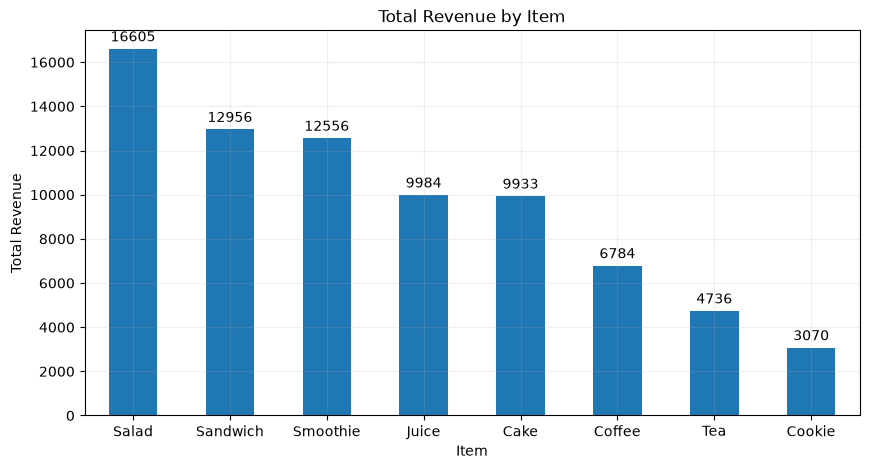

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

revenue_by_item = (
    df_clean.groupby("Item")["Total Spent"]
    .sum()
    .sort_values(ascending=False)
)

ax = revenue_by_item.plot(
    kind="bar",
    figsize=(10, 5)
)

ax.bar_label(
    ax.containers[0],
    fmt="%.0f",
    padding=3
)

revenue_by_item.plot(kind="bar", figsize=(10,5))

plt.title("Total Revenue by Item")
plt.xlabel("Item")
plt.ylabel("Total Revenue")
plt.grid(alpha=.2)
plt.xticks(rotation=0)
plt.show()

Kesimpulan: Salad menjadi penyumbang revenue terbesar bagi cafe, sehingga produk ini perlu dipertahankan ketersediaan dan kualitasnya.

### Quantity Sold per Item

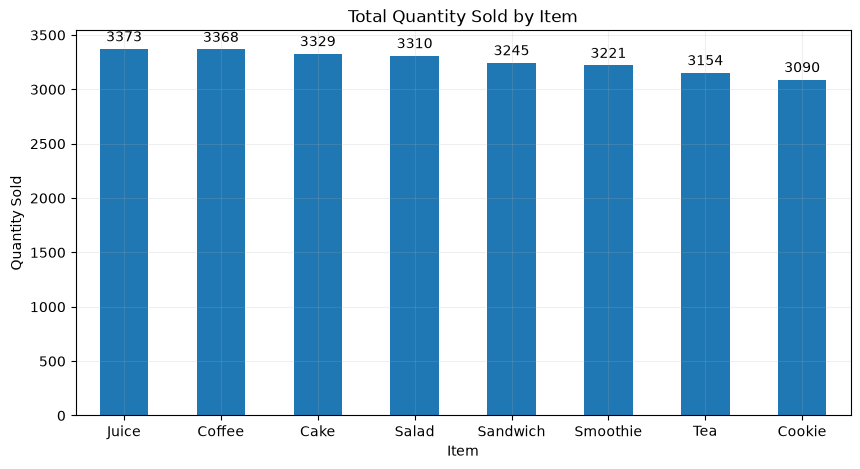

In [35]:
sales_by_item = (
    df_clean.groupby("Item")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

ax = sales_by_item.plot(
    kind="bar",
    figsize=(10, 5)
)

ax.bar_label(
    ax.containers[0],
    fmt="%.0f",
    padding=3
)

sales_by_item.plot(kind="bar", figsize=(10,5))

plt.title("Total Quantity Sold by Item")
plt.xlabel("Item")
plt.ylabel("Quantity Sold")
plt.grid(alpha=.2)
plt.xticks(rotation=0)
plt.show()

Kesimpulan: Coffee merupakan item yang paling banyak terjual dibandingkan item lainnya, menunjukkan bahwa Coffee memiliki permintaan pelanggan yang tinggi. Oleh karena itu, ketersediaan stok Coffee perlu diprioritaskan untuk menjaga penjualan.

### Revenue per Month

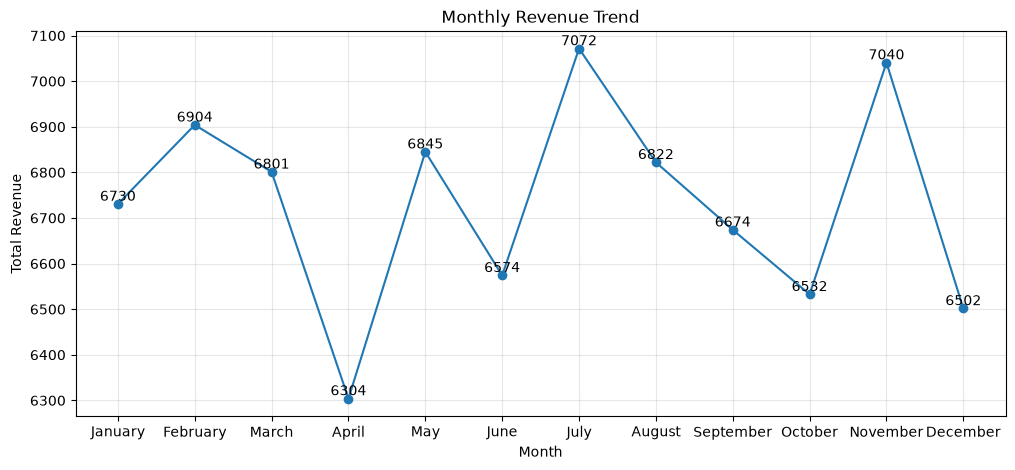

In [36]:
monthly_revenue = (
    df_clean.groupby("Month")["Total Spent"]
    .sum()
)

monthly_revenue.plot(
    marker="o",
    figsize=(12,5)
)

for i, value in enumerate(monthly_revenue.values):
    plt.text(
        i,
        value,
        f"{value:.0f}",
        ha="center",
        va="bottom"
    )


order = ['January','February','March','April','May','June','July','August','September','October','November','December']
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=0)
plt.grid(True, alpha=0.3)
plt.xticks(range(12), order)

plt.show()

Kesimpulan: Bulan Februari mencatat revenue yang jauh lebih tinggi dibandingkan bulan lainnya. Hal ini menunjukkan bahwa Februari merupakan periode dengan performa penjualan paling kuat dan dapat menjadi acuan untuk mengidentifikasi faktor yang mendorong peningkatan revenue.

### Revenue by day

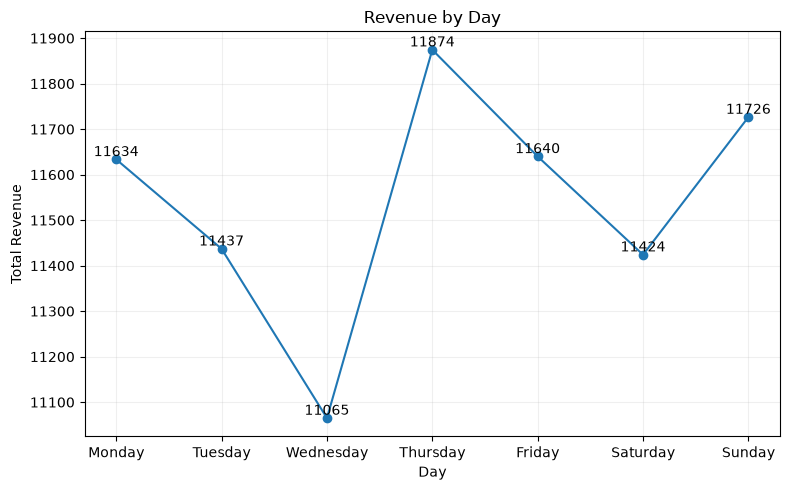

In [37]:
plt.figure(figsize=(8,5))

order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

daily_revenue = (
    df_clean.groupby('Day')['Total Spent']
    .sum()
    .reindex(order)
)

# Line chart
plt.plot(
    range(len(order)),
    daily_revenue.values,
    marker='o'
)

# Menampilkan angka di setiap titik
for i, value in enumerate(daily_revenue.values):
    plt.text(
        i,
        value,
        f'{value:.0f}',
        ha='center',
        va='bottom'
    )

plt.title('Revenue by Day')
plt.xlabel('Day')
plt.ylabel('Total Revenue')
plt.xticks(range(len(order)), order)
plt.grid(alpha=.2)

plt.tight_layout()
plt.show()

Kesimpulan: Hari Senin merupakan hari dengan total penjualan tertinggi dibandingkan hari lainnya. Hal ini menunjukkan bahwa awal minggu menjadi periode yang paling potensial bagi perusahaan untuk meningkatkan penjualan, sehingga promosi dan persediaan dapat lebih diprioritaskan pada hari Senin.

### Monthly Revenue by Item

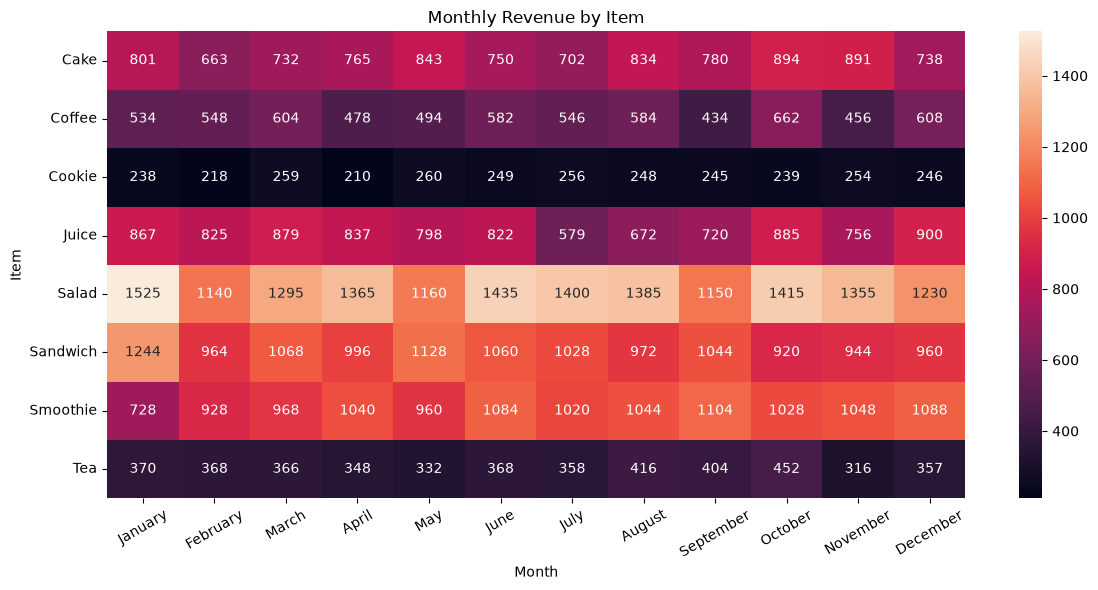

In [38]:
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

monthly_item = pd.pivot_table(
    df_clean,
    values="Total Spent",
    index="Item",
    columns="Month",
    aggfunc="sum"
)

# Urutkan bulan dari Januari sampai Desember
monthly_item = monthly_item.reindex(columns=month_order)

plt.figure(figsize=(12, 6))

sns.heatmap(
    monthly_item,
    annot=True,
    fmt=".0f"
)

plt.title("Monthly Revenue by Item")
plt.xlabel("Month")
plt.xticks(rotation=30)
plt.ylabel("Item")

plt.tight_layout()
plt.show()

Kesimpulan: Februari menjadi bulan dengan lonjakan penjualan tertinggi (peak performance) across-the-board, mencapai total revenue 10.831 dollar. Angka ini jauh melampaui rata-rata bulan lainnya yang berada di kisaran 6.800–7.300. Puncak pendapatan tertinggi pada bulan Februari dicapai oleh Salad (1.970), Sandwich (1.664), Smoothie (1.578), dan Juice (1.338).

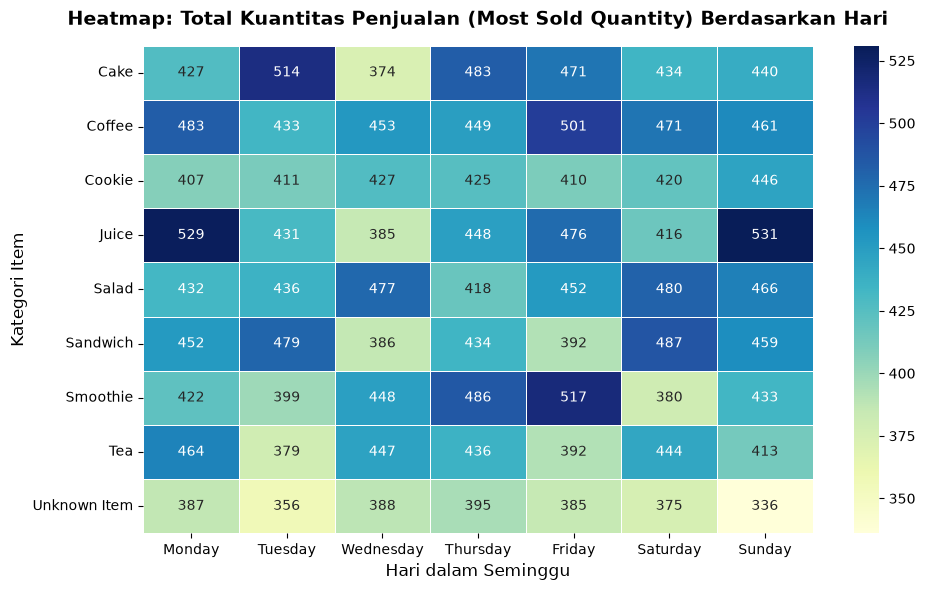

In [46]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Persiapan Data: Salin df_clean dan tangani NaN pada Item dan Day
df_heat = df_clean.copy()
df_heat['Item'] = df_heat['Item'].fillna('Unknown Item')
df_heat['Day'] = df_heat['Day'].fillna('Unknown Day')

# Urutan hari kronologis (Senin - Minggu)
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# 2. Membuat Pivot Table untuk Total Kuantitas (Quantity) Item per Hari
heatmap_data = pd.pivot_table(
    df_heat,
    index='Item',
    columns='Day',
    values='Quantity',
    aggfunc='sum',     # Menjumlahkan total kuantitas terjual
    fill_value=0
)

# Sesuaikan urutan kolom berdasarkan day_order yang ada di data
existing_days = [d for d in day_order if d in heatmap_data.columns]
heatmap_data = heatmap_data[existing_days]

# 3. Membuat Heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(
    heatmap_data, 
    annot=True,       # Menampilkan angka total kuantitas di dalam sel
    fmt='g',          # Format angka
    cmap='YlGnBu',    # Tema warna gradasi (Yellow-Green-Blue)
    linewidths=0.5,   # Garis pemisah antar sel
    cbar=True
)

# 4. Pengaturan Estetika Grafik
plt.title('Heatmap: Total Kuantitas Penjualan (Most Sold Quantity) Berdasarkan Hari', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Hari dalam Seminggu', fontsize=12)
plt.ylabel('Kategori Item', fontsize=12)
plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

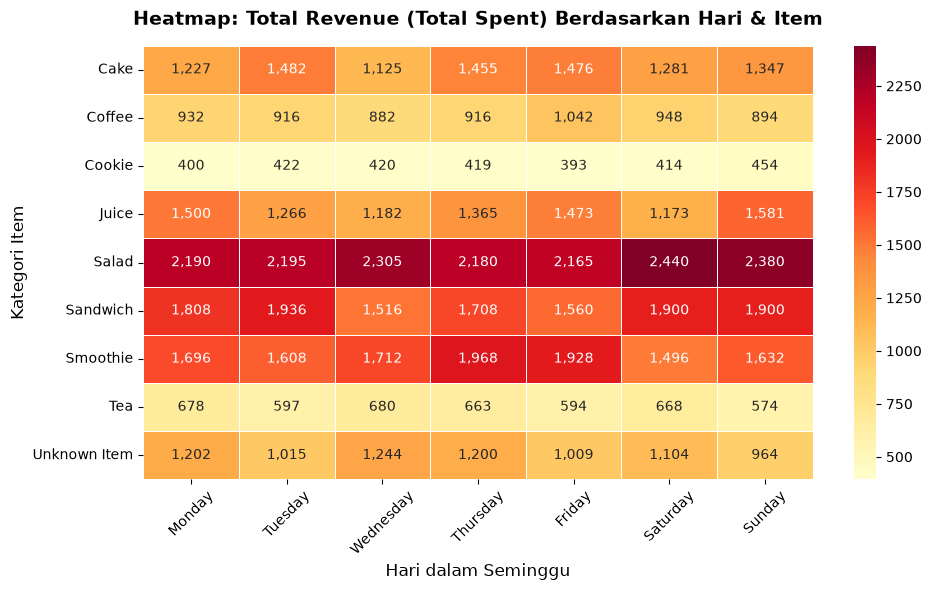

In [40]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Persiapan Data: Salin df_clean dan tangani NaN pada Item dan Day
df_heat_rev = df_clean.copy()
df_heat_rev['Item'] = df_heat_rev['Item'].fillna('Unknown Item')
df_heat_rev['Day'] = df_heat_rev['Day'].fillna('Unknown Day')

# Urutan hari kronologis (Senin - Minggu)
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# 2. Membuat Pivot Table untuk Total Revenue (Total Spent) Item per Hari
heatmap_revenue = pd.pivot_table(
    df_heat_rev,
    index='Item',
    columns='Day',
    values='Total Spent',
    aggfunc='sum',     # Menjumlahkan total pendapatan (revenue)
    fill_value=0
)

# Sesuaikan urutan kolom berdasarkan day_order yang ada di data
existing_days = [d for d in day_order if d in heatmap_revenue.columns]
heatmap_revenue = heatmap_revenue[existing_days]

# 3. Membuat Heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(
    heatmap_revenue, 
    annot=True,       # Menampilkan angka total revenue di dalam sel
    fmt=',.0f',       # Format angka dengan pemisah ribuan (misal: 150000)
    cmap='YlOrRd',    # Tema warna oranye-merah untuk menunjukkan nilai finansial/pendapatan
    linewidths=0.5,   # Garis pemisah antar sel
    cbar=True
)

# 4. Pengaturan Estetika Grafik
plt.title('Heatmap: Total Revenue (Total Spent) Berdasarkan Hari & Item', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Hari dalam Seminggu', fontsize=12)
plt.ylabel('Kategori Item', fontsize=12)
plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

### Missing Payment Method by Location

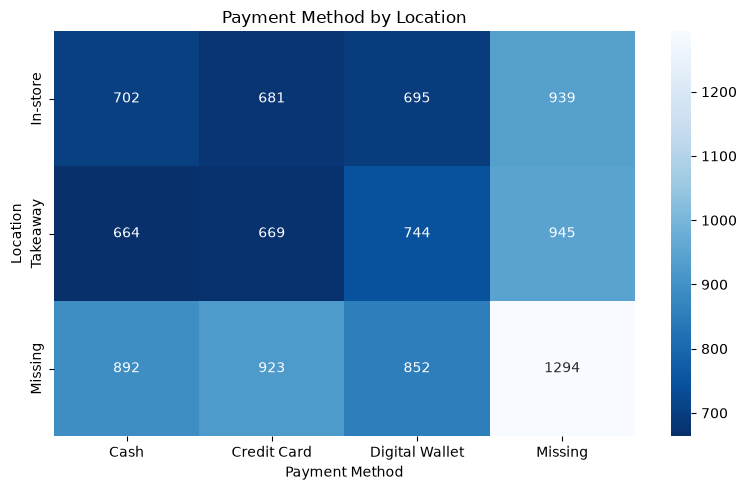

In [41]:
payment_location = pd.crosstab(
    df_clean["Location"].fillna("Missing"),
    df_clean["Payment Method"].fillna("Missing")
)

# Atur urutan Location
location_order = ["In-store", "Takeaway", "Missing"]

payment_location = payment_location.reindex(
    index=location_order,
    fill_value=0
)

plt.figure(figsize=(8, 5))

sns.heatmap(
    payment_location,
    annot=True,
    fmt="d",
    cmap="Blues_r"
)

plt.title("Payment Method by Location")
plt.xlabel("Payment Method")
plt.ylabel("Location")

plt.tight_layout()
plt.show()

Kategori Missing mendominasi dataset. Sebanyak 31,78% data metode pembayaran dan 39,61% data lokasi tidak tercatat. Di luar data yang hilang, proporsi penggunaan Cash (22,58%), Credit Card (22,73%), dan Digital Wallet (22,91%) hampir sama persis. Tidak ada metode pembayaran yang dominan secara signifikan. Makan di tempat (In-store) dan bawa pulang (Takeaway) memiliki jumlah yang setara, masing-masing berada di angka ~30% dari keseluruhan dataset.

### Spending Level Distribution

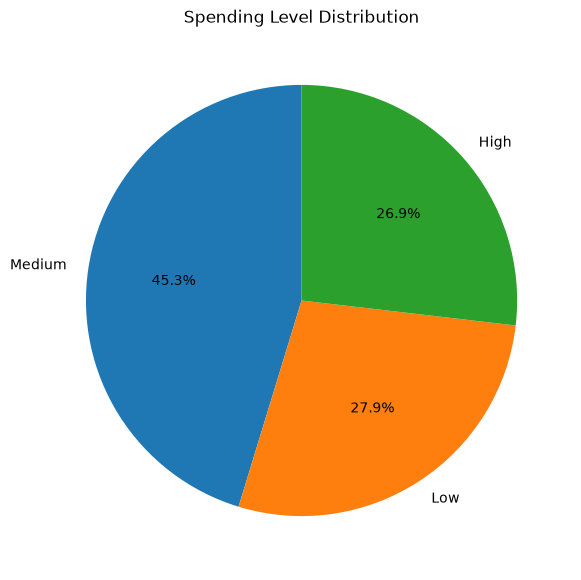

In [42]:
spending_level = df_clean["Spending Level"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    spending_level.values,
    labels=spending_level.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Spending Level Distribution")
plt.show()

Kesimpulan: Mayoritas transaksi berada pada kategori Medium Spending, yang menunjukkan bahwa pelanggan cenderung melakukan pembelian dengan nilai transaksi sedang. Transaksi dengan kategori High Spending memiliki jumlah yang lebih sedikit sehingga perusahaan dapat mempertimbangkan strategi bundling atau promo untuk meningkatkan nilai transaksi pelanggan.

=== TABEL AGREGASI: TOTAL REVENUE BERDASARKAN ITEM & LOKASI ===
Location      In-store  Takeaway  Unknown Location
Item                                              
Cake            2892.0    3009.0            4032.0
Coffee          1854.0    2114.0            2816.0
Cookie           905.0    1045.0            1120.0
Juice           3108.0    2850.0            4026.0
Salad           5405.0    4835.0            6365.0
Sandwich        4320.0    3936.0            4700.0
Smoothie        3536.0    3496.0            5524.0
Tea             1459.5    1455.0            1821.0
Unknown Item    2426.5    2489.5            3224.0


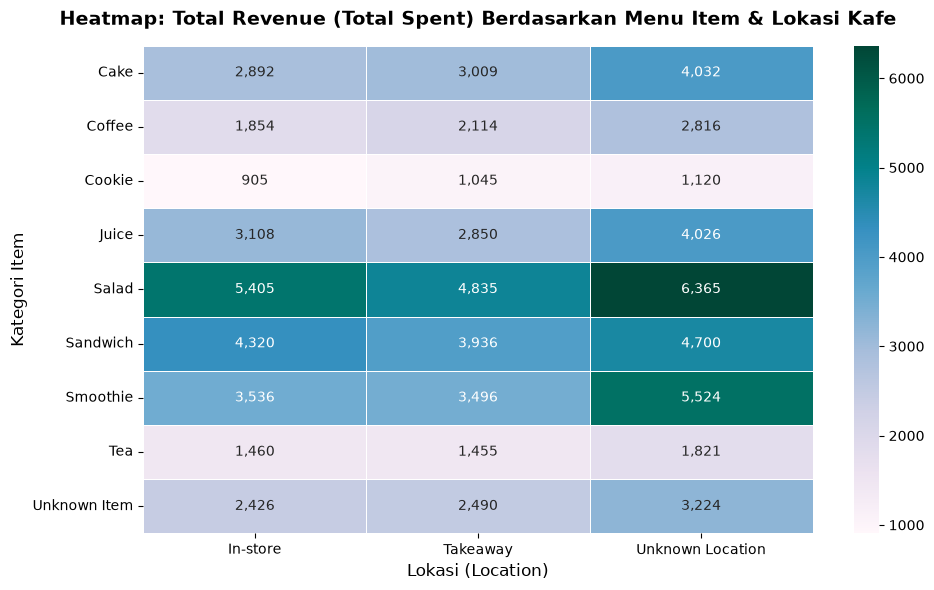

In [43]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Persiapan Data: Salin df_clean dan tangani NaN pada Item dan Location
df_heat_loc = df_clean.copy()
df_heat_loc['Item'] = df_heat_loc['Item'].fillna('Unknown Item')
df_heat_loc['Location'] = df_heat_loc['Location'].fillna('Unknown Location')

# 2. Membuat Pivot Table untuk Total Revenue (Total Spent) per Item dan Location
heatmap_loc_rev = pd.pivot_table(
    df_heat_loc,
    index='Item',
    columns='Location',
    values='Total Spent',
    aggfunc='sum',     # Menjumlahkan total pendapatan (revenue)
    fill_value=0
)

print("=== TABEL AGREGASI: TOTAL REVENUE BERDASARKAN ITEM & LOKASI ===")
print(heatmap_loc_rev)

# 3. Membuat Heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(
    heatmap_loc_rev, 
    annot=True,       # Menampilkan angka total revenue di dalam sel
    fmt=',.0f',       # Format angka dengan pemisah ribuan
    cmap='PuBuGn',    # Tema warna gradasi (Purple-Blue-Green)
    linewidths=0.5,   # Garis pemisah antar sel
    cbar=True
)

# 4. Pengaturan Estetika Grafik
plt.title('Heatmap: Total Revenue (Total Spent) Berdasarkan Menu Item & Lokasi Kafe', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Lokasi (Location)', fontsize=12)
plt.ylabel('Kategori Item', fontsize=12)
plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

## Key Business Insight

1. Mempertahankan stok produk dengan penjualan tinggi
2. Meningkatkan promosi produk dengan revenue tinggi
3. Mengoptimalkan stok dan tenaga kerja pada periode dengan penjualan tinggi
4. Mengevaluasi metode pembayaran yang paling banyak digunakan
5. Meningkatkan kualitas pencatatan Location dan Payment Method untuk menghasilkan analisis yang lebih akurat.